In [9]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import torch.optim as optim

# 通过路径的匹配，获取所有图片文件
import glob

In [10]:
img_dir = r'./dataset2/*.jpg'
imgs = glob.glob(img_dir)
# imgs

In [11]:
species = ['cloudy','haze','rainy','sunny','snow','thunder']

In [12]:
species_to_idx = {}
for index,value in enumerate(species):
    species_to_idx[value] = index
species_to_idx

{'cloudy': 0, 'haze': 1, 'rainy': 2, 'sunny': 3, 'snow': 4, 'thunder': 5}

In [13]:
ids_to_species = {}
for index,value in enumerate(species):
    ids_to_species[index] = value
ids_to_species

{0: 'cloudy', 1: 'haze', 2: 'rainy', 3: 'sunny', 4: 'snow', 5: 'thunder'}

In [14]:
labels=[]
# 循环提取，路径里的标签
for img in imgs:
    for index,value in enumerate(species):
        if value in img:
            labels.append(value)
len(labels)

7390

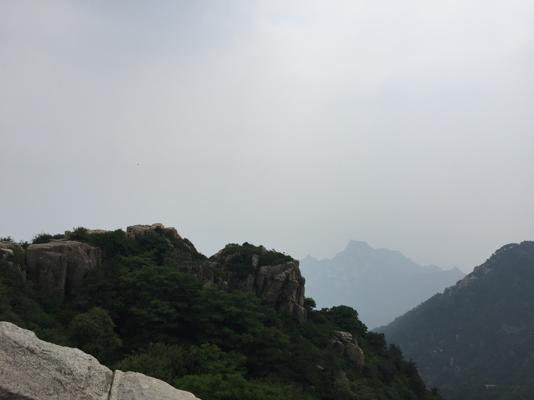

In [15]:
from PIL import Image
from matplotlib import pyplot as plt
testImg = Image.open('dataset2/cloudy_00123.jpg')
testImg

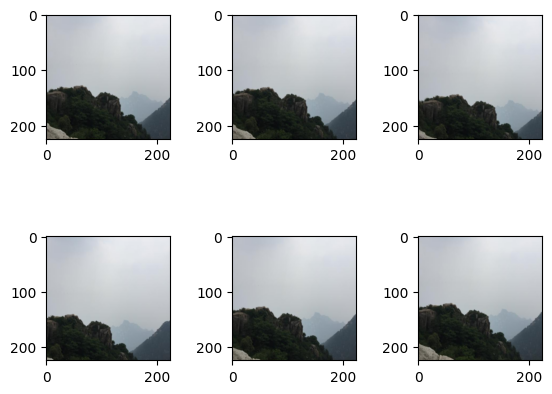

In [16]:
transformRandomCrop = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.RandomCrop((224,224))
])
for i in range(6):
    img = transformRandomCrop(testImg)
    plt.subplot(2,3,i+1)
    plt.imshow(img)

plt.subplots_adjust(wspace=0.5,hspace=0.5)

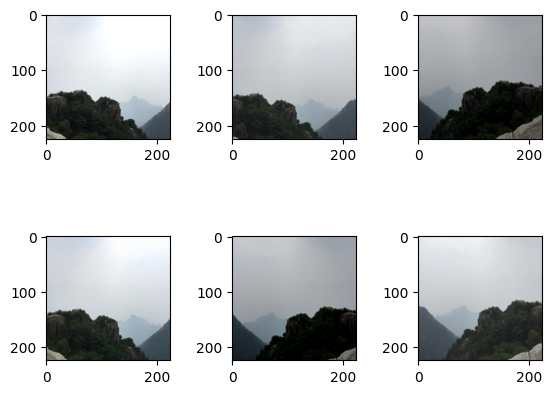

In [17]:
# 添加水平翻转
transformRandomCrop = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    # 上下翻转
    # transforms.RandomVerticalFlip(p=0.5),
    # 随机旋转一定角度
    # transforms.RandomRotation(90),
    transforms.Resize((256,256)),
    transforms.RandomCrop((224,224)),
    transforms.ColorJitter(brightness=0.2,contrast=0.2,saturation=0.2,hue=0.01),
    # 随机灰度变化
    # transforms.RandomGrayscale(p=0.1)
])
for i in range(6):
    img = transformRandomCrop(testImg)
    plt.subplot(2,3,i+1)
    plt.imshow(img)

plt.subplots_adjust(wspace=0.5,hspace=0.5)

In [18]:
from torchvision import transforms

# 设置转换函数
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    # 上下翻转
    # transforms.RandomVerticalFlip(p=0.5),
    # 随机旋转一定角度
    # transforms.RandomRotation(90),
    transforms.Resize((256,256)),
    transforms.RandomCrop((224,224)),
    transforms.ColorJitter(brightness=0.2,contrast=0.2,saturation=0.2,hue=0.01),
    # 转换相同大小
    transforms.Resize((224,224)),
    # 转换张量
    transforms.ToTensor(),
    # 标准化
    transforms.Normalize(mean=[0.5,0.5,0.5],std=[0.5,0.5,0.5])
])

In [19]:
from torch.utils import data
# 自定义数据集
from PIL import Image

class WT_dataset(data.Dataset):
    def __init__(self,imgs_path,labels):
        self.imgs_path = imgs_path
        self.labels = labels

    def __getitem__(self,index):
        img_path = self.imgs_path[index]
        label = self.labels[index]
        # 拿到地址获取图片数据
        pilImg = Image.open(img_path)
        pilImg = pilImg.convert('RGB')
        pilImg = transform(pilImg)
        # 将实数转换为张量
        return pilImg,torch.tensor(species_to_idx[label])

    def __len__(self):
        return len(self.imgs_path)

In [20]:
dataset = WT_dataset(imgs,labels)
dataset

In [21]:
# 拆分80%训练，20%测试
train_count = int(0.9*len(dataset))
test_count = len(dataset)-train_count
print(train_count,test_count)

6651 739


In [22]:
# 随机打乱数据集
train_dataset,test_dataset = data.random_split(dataset,[train_count,test_count])
len(train_dataset),len(test_dataset)

(6651, 739)

In [23]:
BATCH_SIZE = 16
train_dl = torch.utils.data.DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True
)
test_dl = torch.utils.data.DataLoader(
    test_dataset,
    batch_size = BATCH_SIZE
)

In [24]:
imgs,label = next(iter(train_dl))
imgs.shape

torch.Size([16, 3, 224, 224])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.81960785..0.58431375].


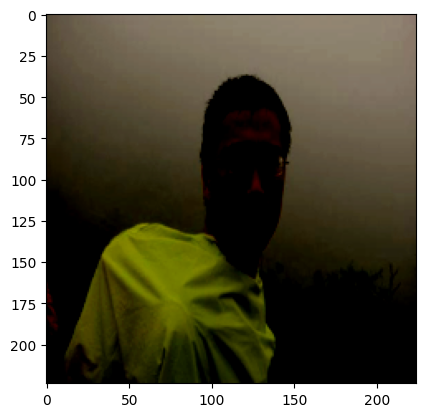

In [25]:
from matplotlib import pyplot as plt
im = imgs[0].permute(1,2,0)
plt.imshow(im)

In [26]:
# # 加载预训练好的vgg16模型
# model = torchvision.models.vgg16(pretrained = True)
# model

import torchvision
from torchvision.models import vgg16, VGG16_Weights

# 标准新版写法，无警告
model = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
model

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [27]:
# dir(torchvision.models)

In [28]:
# 固定学习经验，解冻features卷积层模块的权重，固定猪特征提取层
for param in model.features.parameters():
    param.requires_grad = False

# 加快训练速度，避免一开始就破坏预训练层学习到的特征经验

In [29]:
# 修改分类器输出层，最后输出6各类别
model.classifier[-1].out_features=6
model

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [30]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)
device

'cuda'

In [31]:
# 定义损失函数
loss_fn = torch.nn.CrossEntropyLoss()
# 定义优化器
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)

In [32]:
# 定义训练函数，从训练加载器里提取训练数据，进行训练
def train(dataLoader,model,loss_fn,optimizer):
    # 获取整个训练数据集大小
    size = len(dataLoader.dataset)
    train_loss,correct=0,0      
    # 循环遍历整个数据集
    for X,Y in dataLoader:
        X,Y=X.to(device),Y.to(device)
        # 进行初步预测
        pred=model(X)
        # 查看误差
        loss = loss_fn(pred,Y)

        # 梯度归零
        optimizer.zero_grad()
        # 反向传播
        loss.backward()
        # 使用优化器更新参数
        optimizer.step()

        # 计算当前准确率
        # 计算准确率不需要更新梯度
        with torch.no_grad():
            # 在10个数据里挑最大值
            correct += (pred.argmax(1)==Y).type(torch.float).sum().item()
            # 获取当前训练的损失值
            train_loss +=loss.item()
    # 计算平均损失和正确率
    train_loss = train_loss / size
    correct = correct/size
    return train_loss,correct
        

In [33]:
# 定义一个测试函数
def test(dataLoader,model):
    # 获取测试集大小
    size = len(dataLoader.dataset)
    train_loss, correct = 0, 0
     # 计算准确率不需要更新梯度
    with torch.no_grad():
        for X,Y in dataLoader:
            X,Y=X.to(device),Y.to(device)
            # 进行初步预测
            pred=model(X)
            # 查看误差
            loss = loss_fn(pred,Y)
            # 在10个数据里挑最大值
            correct += (pred.argmax(1)==Y).type(torch.float).sum().item()
            # 获取当前训练的损失值
            train_loss +=loss.item()
    # 计算平均损失和正确率
    train_loss = train_loss / size
    correct = correct/size
    return train_loss,correct

In [36]:
# 训练多轮
epochs = 10
train_acc=[]
test_acc=[]


# 保存最佳的准确率
best_acc = 0.0
best_acc_index=0
for epoch in range(epochs):
    epoch_loss,epoch_acc = train(train_dl,model,loss_fn,optimizer)
    epoch_test_loss,epoch_test_acc = test(test_dl,model)
    train_acc.append(epoch_acc)
    test_acc.append(epoch_test_acc)
    print('epoch:{},train_loss:{},train_acc{}'.format(epoch,epoch_loss,epoch_acc))
    print('epoch:{},test_loss:{},test_acc{}'.format(epoch,epoch_test_loss,epoch_test_acc))
    print('---------------------------------')
    if epoch_test_acc > best_acc:
        print('保存最佳准确率模型',epoch_test_acc)
        best_acc = epoch_test_acc
        best_acc_index = best_acc_index+1
        # 保存模型结构，包含参数
        torch.save(model,'best_model.pth')
        # 保存参数
        # torch.save(model1.state_dict(),'best_model_weights'+str(best_acc_index)+'.pth')

epoch:0,train_loss:0.0401549542558281,train_acc0.8409261765148098
epoch:0,test_loss:0.10933275240522598,test_acc0.6589986468200271
---------------------------------
保存最佳准确率模型 0.6589986468200271
epoch:1,train_loss:0.035510373335830736,train_acc0.8481431363704706
epoch:1,test_loss:0.10634598467141107,test_acc0.6982408660351827
---------------------------------
保存最佳准确率模型 0.6982408660351827
epoch:2,train_loss:0.0345937033772198,train_acc0.8567132761990678
epoch:2,test_loss:0.11380719319893316,test_acc0.6617050067658998
---------------------------------
epoch:3,train_loss:0.036639109053854146,train_acc0.858517516162983
epoch:3,test_loss:0.11273987867008688,test_acc0.706359945872801
---------------------------------
保存最佳准确率模型 0.706359945872801


KeyboardInterrupt: 

In [ ]:
# 微调：先冻结预训练大模型，进行初始训练，训练的练到一定程度，解冻模型所有层，进行进一步的训练
for param in model.features.parameters():
    param.requires_grad = True

optimzer = torch.optim.Adam(model.parameters(),lr=0.00001)

In [ ]:
# 训练多轮
epochs = 10
train_acc=[]
test_acc=[]


# 保存最佳的准确率
best_acc = 0.0
best_acc_index=0
for epoch in range(epochs):
    epoch_loss,epoch_acc = train(train_dl,model,loss_fn,optimizer)
    epoch_test_loss,epoch_test_acc = test(test_dl,model)
    train_acc.append(epoch_acc)
    test_acc.append(epoch_test_acc)
    print('epoch:{},train_loss:{},train_acc{}'.format(epoch,epoch_loss,epoch_acc))
    print('epoch:{},test_loss:{},test_acc{}'.format(epoch,epoch_test_loss,epoch_test_acc))
    print('---------------------------------')
    if epoch_test_acc > best_acc:
        print('保存最佳准确率模型',epoch_test_acc)
        best_acc = epoch_test_acc
        best_acc_index = best_acc_index+1
        # 保存模型结构，包含参数
        torch.save(model,'best_model.pth')
        # 保存参数
        # torch.save(model1.state_dict(),'best_model_weights'+str(best_acc_index)+'.pth')